In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Data Prep

summer: shape=(6, 1376, 1470), crs=EPSG:32632
winter: shape=(6, 1376, 1470), crs=EPSG:32632
Scene size: 1376 x 1470 pixels (~13.8 x 14.7 km)


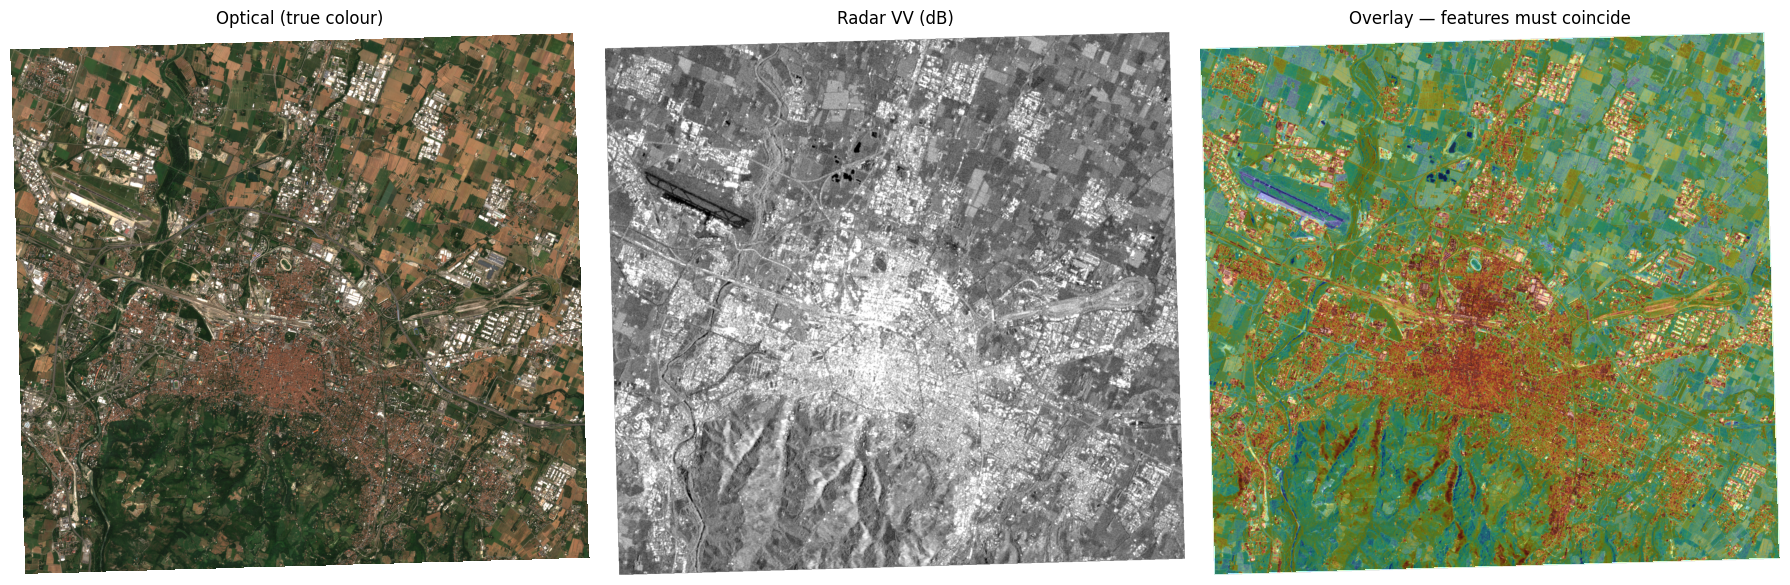

Block layout (row, col) → split. (0,0) = top-left/NW of your box:
   (0,0):train | (0,1):test  | (0,2):test 
   (1,0):train | (1,1):train | (1,2):val  
   (2,0):train | (2,1):train | (2,2):train
Patches kept: 490  ->  {'test': 114, 'train': 326, 'val': 50}
Normalization stats (train split only):
  B2: mean=0.062  std=0.045
  B3: mean=0.083  std=0.048
  B4: mean=0.089  std=0.057
  B8: mean=0.239  std=0.099
  VV: mean=-8.127  std=4.176
  VH: mean=-15.592  std=3.710
Done. Wrote 490 patches, manifest.csv, norm_stats.json to /content/drive/MyDrive/q3_pipeline


In [ ]:
DRIVE_DIR   = "/content/drive/MyDrive/GEE_exports"
TIFS = {  # season -> path
    "summer": f"{DRIVE_DIR}/bologna_optical_sar_summer2023.tif",
    "winter": f"{DRIVE_DIR}/bologna_optical_sar_winter2023.tif",
}
OUT_DIR     = "/content/drive/MyDrive/q3_pipeline"   # everything is saved here

PATCH   = 128     # patch size in pixels
STRIDE  = 64      # 50% overlap
GRID    = 3       # split the scene into GRID x GRID spatial blocks

TEST_BLOCKS = [(0, 1), (0, 2)]   # default: northern strip (Bologna's
VAL_BLOCKS  = [(1, 2)]           # subsidence leans north/east)

# Quality thresholds for keeping a patch
MAX_NODATA_FRAC = 0.05
MAX_WATER_FRAC  = 0.30
NDWI_WATER_THRESHOLD = 0.2

# Band order in the GeoTIFF (as exported from GEE)
BANDS = ["B2", "B3", "B4", "B8", "VV", "VH"]
OPTICAL_IDX = [0, 1, 2, 3]      # model input
RADAR_IDX   = [4, 5]            # model target

import os, json, csv
import numpy as np
import rasterio
import matplotlib.pyplot as plt

os.makedirs(f"{OUT_DIR}/patches", exist_ok=True)

stacks = {}
profiles = {}
for season, path in TIFS.items():
    with rasterio.open(path) as src:
        arr = src.read().astype(np.float32)          # (6, H, W)
        stacks[season] = arr
        profiles[season] = {"transform": src.transform, "crs": src.crs,
                            "shape": arr.shape}
        print(f"{season}: shape={arr.shape}, crs={src.crs}")

shapes = {s: a.shape for s, a in stacks.items()}
assert len(set(shapes.values())) == 1, f"Seasons have different shapes: {shapes}"
H, W = stacks["summer"].shape[1:]
print(f"Scene size: {H} x {W} pixels (~{H*10/1000:.1f} x {W*10/1000:.1f} km)")

# Roads/rivers must sit in the same place in optical and radar.
s = stacks["summer"]
rgb = np.clip(np.stack([s[2], s[1], s[0]], -1) / 0.3, 0, 1)   # B4,B3,B2
vv  = s[4]

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(rgb);                 ax[0].set_title("Optical (true colour)")
ax[1].imshow(vv, cmap="gray", vmin=-20, vmax=0); ax[1].set_title("Radar VV (dB)")
ax[2].imshow(rgb); ax[2].imshow(vv, cmap="jet", vmin=-20, vmax=0, alpha=0.35)
ax[2].set_title("Overlay — features must coincide")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/alignment_check.png", dpi=120)
plt.show()

def make_masks(arr):
    """Return (nodata_mask, water_mask) as boolean (H, W) arrays."""
    nodata = ~np.isfinite(arr).all(axis=0)
    nodata |= (arr[OPTICAL_IDX].sum(axis=0) == 0)          # empty optical
    green, nir = arr[1], arr[3]                            # B3, B8
    with np.errstate(divide="ignore", invalid="ignore"):
        ndwi = (green - nir) / (green + nir)
    water = np.nan_to_num(ndwi, nan=0.0) > NDWI_WATER_THRESHOLD
    return nodata, water

masks = {season: make_masks(arr) for season, arr in stacks.items()}

bh, bw = H // GRID, W // GRID
def block_of(r, c):
    return (min(r // bh, GRID - 1), min(c // bw, GRID - 1))

def split_of(block):
    if block in TEST_BLOCKS: return "test"
    if block in VAL_BLOCKS:  return "val"
    return "train"

print("Block layout (row, col) → split. (0,0) = top-left/NW of your box:")
for r in range(GRID):
    print("   " + " | ".join(f"({r},{c}):{split_of((r,c)):5s}" for c in range(GRID)))

records = []
pid = 0
for season, arr in stacks.items():
    nodata, water = masks[season]
    for r in range(0, H - PATCH + 1, STRIDE):
        for c in range(0, W - PATCH + 1, STRIDE):
            # a patch must sit ENTIRELY inside one block, or splits leak
            b_tl = block_of(r, c)
            b_br = block_of(r + PATCH - 1, c + PATCH - 1)
            if b_tl != b_br:
                continue
            nd = nodata[r:r+PATCH, c:c+PATCH].mean()
            wt = water [r:r+PATCH, c:c+PATCH].mean()
            if nd > MAX_NODATA_FRAC or wt > MAX_WATER_FRAC:
                continue
            patch = arr[:, r:r+PATCH, c:c+PATCH]
            fname = f"patches/p{pid:05d}_{season}.npy"
            np.save(f"{OUT_DIR}/{fname}", patch)
            records.append({"id": pid, "file": fname, "season": season,
                            "row": r, "col": c, "split": split_of(b_tl),
                            "water_frac": round(float(wt), 3)})
            pid += 1

counts = {}
for rec in records:
    counts[rec["split"]] = counts.get(rec["split"], 0) + 1
print(f"Patches kept: {len(records)}  ->  {counts}")
assert counts.get("train", 0) > 100, "Too few training patches — check masks/blocks."

train_files = [f"{OUT_DIR}/{r['file']}" for r in records if r["split"] == "train"]
acc_sum  = np.zeros(len(BANDS)); acc_sq = np.zeros(len(BANDS)); n_px = 0
n_px = np.zeros(len(BANDS))          # per-band count of FINITE pixels
for f in train_files:
    p = np.load(f)                              # (6, 128, 128)
    flat = p.reshape(len(BANDS), -1)
    finite = np.isfinite(flat)                  # ignore nan/inf (masked pixels)
    flat0 = np.where(finite, flat, 0.0)         # zero-out non-finite for summing
    acc_sum += flat0.sum(axis=1)
    acc_sq  += (flat0 ** 2).sum(axis=1)
    n_px    += finite.sum(axis=1)
n_px = np.maximum(n_px, 1)                       # guard against divide-by-zero
mean = acc_sum / n_px
std  = np.sqrt(np.maximum(acc_sq / n_px - mean ** 2, 1e-8))
stats = {"bands": BANDS, "mean": mean.tolist(), "std": std.tolist()}
with open(f"{OUT_DIR}/norm_stats.json", "w") as fh:
    json.dump(stats, fh, indent=2)
print("Normalization stats (train split only):")
for b, m, s_ in zip(BANDS, mean, std):
    print(f"  {b}: mean={m:.3f}  std={s_:.3f}")

with open(f"{OUT_DIR}/manifest.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=records[0].keys())
    w.writeheader(); w.writerows(records)
print(f"Done. Wrote {len(records)} patches, manifest.csv, norm_stats.json"
      f" to {OUT_DIR}")

#Train

Device: cuda (if this says cpu, switch Colab runtime to GPU)
{'train': 326, 'val': 50, 'test': 114}
1.928738 M parameters
epoch   0  train L1 0.6940  val L1 0.7471  <- saved
epoch   1  train L1 0.6116  val L1 0.7640
epoch   2  train L1 0.5888  val L1 0.7634
epoch   3  train L1 0.5858  val L1 0.7735
epoch   4  train L1 0.5739  val L1 0.6035  <- saved
epoch   5  train L1 0.5725  val L1 0.6133
epoch   6  train L1 0.5649  val L1 0.6175
epoch   7  train L1 0.5552  val L1 0.6040
epoch   8  train L1 0.5547  val L1 0.6198
epoch   9  train L1 0.5494  val L1 0.5999  <- saved
epoch  10  train L1 0.5459  val L1 0.6053
epoch  11  train L1 0.5446  val L1 0.5956  <- saved
epoch  12  train L1 0.5472  val L1 0.5985
epoch  13  train L1 0.5483  val L1 0.5983
epoch  14  train L1 0.5407  val L1 0.5933  <- saved
epoch  15  train L1 0.5341  val L1 0.5972
epoch  16  train L1 0.5355  val L1 0.5923  <- saved
epoch  17  train L1 0.5279  val L1 0.5936
epoch  18  train L1 0.5292  val L1 0.5790  <- saved
epoch  19 

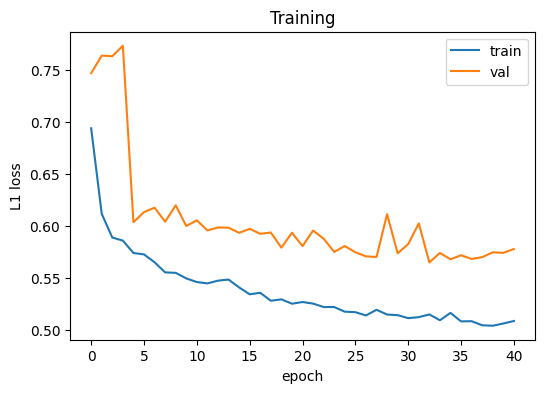

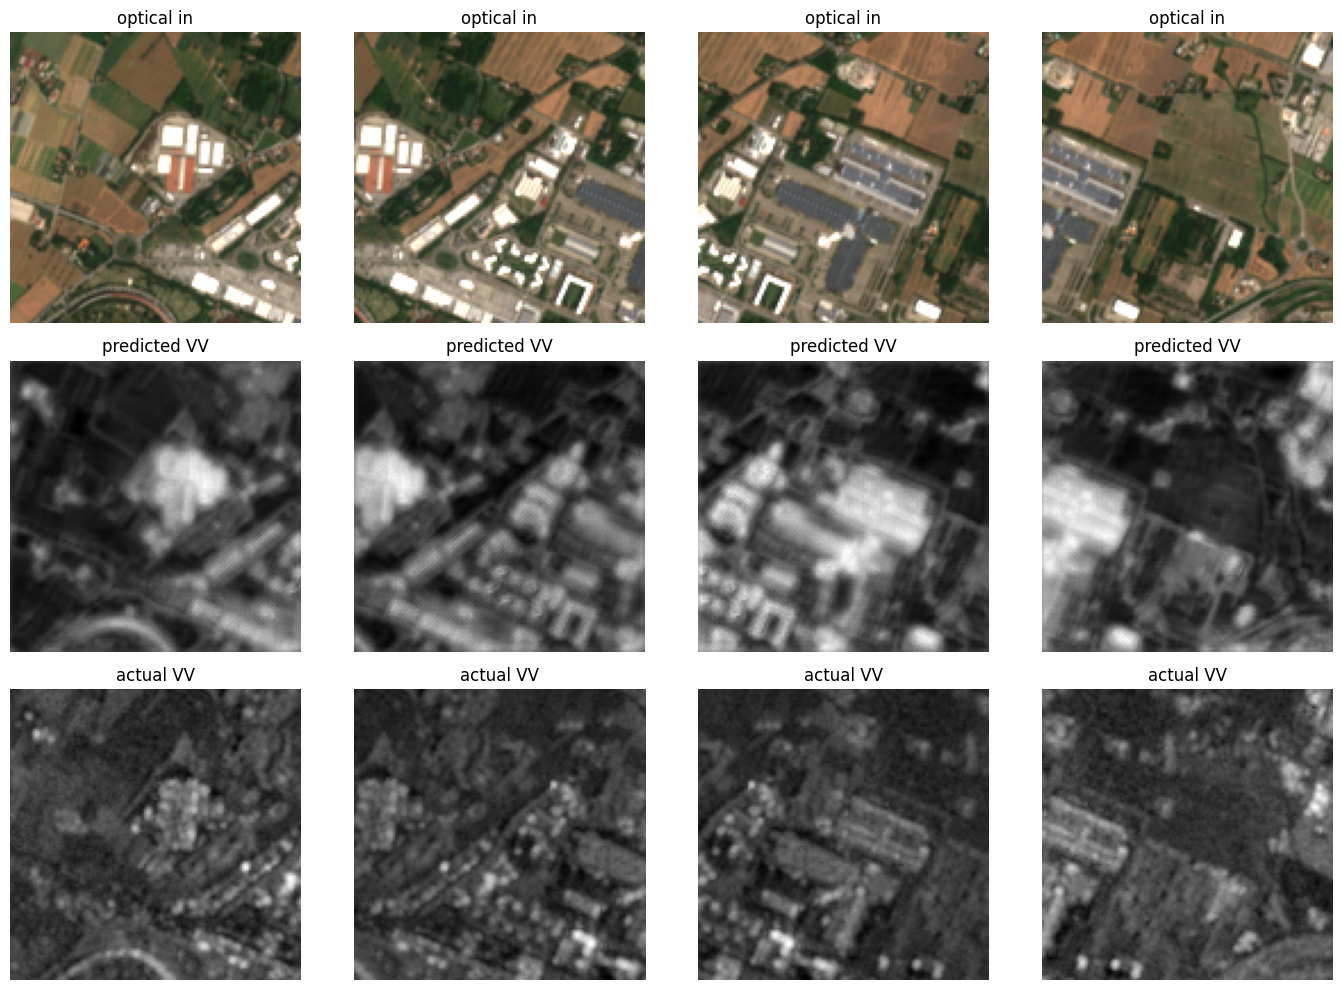

Best val L1 = 0.5648 (epoch 32). Model saved to best_model.pt


In [ ]:
OUT_DIR    = "/content/drive/MyDrive/q3_pipeline"
BATCH      = 32
EPOCHS     = 60
LR         = 1e-3
PATIENCE   = 8          # early stop if val loss doesn't improve
SEED       = 0

OPTICAL_IDX = [0, 1, 2, 3]
RADAR_IDX   = [4, 5]

import json, csv, random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "(if this says cpu, switch Colab runtime to GPU)")

with open(f"{OUT_DIR}/norm_stats.json") as fh:
    stats = json.load(fh)
MEAN = np.array(stats["mean"], dtype=np.float32)[:, None, None]
STD  = np.array(stats["std"],  dtype=np.float32)[:, None, None]

with open(f"{OUT_DIR}/manifest.csv") as fh:
    manifest = list(csv.DictReader(fh))

class PatchDataset(Dataset):
    """Yields (optical[4,128,128], radar[2,128,128]), both normalized.
    Augmentation (flips / 90-degree rotations) is applied identically to
    input and target — they must stay geometrically locked together."""
    def __init__(self, records, augment=False):
        self.records, self.augment = records, augment
    def __len__(self):
        return len(self.records)
    def __getitem__(self, i):
        p = np.load(f"{OUT_DIR}/{self.records[i]['file']}")   # (6,128,128)
        p = np.nan_to_num(p, nan=0.0)
        p = (p - MEAN) / STD
        if self.augment:
            if random.random() < 0.5: p = p[:, ::-1, :]
            if random.random() < 0.5: p = p[:, :, ::-1]
            p = np.rot90(p, k=random.randint(0, 3), axes=(1, 2))
        p = np.ascontiguousarray(p)
        x = torch.from_numpy(p[OPTICAL_IDX])
        y = torch.from_numpy(p[RADAR_IDX])
        return x, y

splits = {s: [r for r in manifest if r["split"] == s]
          for s in ("train", "val", "test")}
print({k: len(v) for k, v in splits.items()})

train_dl = DataLoader(PatchDataset(splits["train"], augment=True),
                      batch_size=BATCH, shuffle=True,  num_workers=2)
val_dl   = DataLoader(PatchDataset(splits["val"]),
                      batch_size=BATCH, shuffle=False, num_workers=2)

def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    """Small U-Net: 4 optical channels in -> 2 radar channels out."""
    def __init__(self, cin=4, cout=2, base=32):
        super().__init__()
        b = base
        self.e1 = conv_block(cin, b);      self.e2 = conv_block(b, 2*b)
        self.e3 = conv_block(2*b, 4*b);    self.e4 = conv_block(4*b, 8*b)
        self.pool = nn.MaxPool2d(2)
        self.u3 = nn.ConvTranspose2d(8*b, 4*b, 2, stride=2); self.d3 = conv_block(8*b, 4*b)
        self.u2 = nn.ConvTranspose2d(4*b, 2*b, 2, stride=2); self.d2 = conv_block(4*b, 2*b)
        self.u1 = nn.ConvTranspose2d(2*b, b,   2, stride=2); self.d1 = conv_block(2*b, b)
        self.head = nn.Conv2d(b, cout, 1)
    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2))
        e4 = self.e4(self.pool(e3))
        d3 = self.d3(torch.cat([self.u3(e4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.head(d1)

model = UNet().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M parameters")

opt   = torch.optim.AdamW(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
loss_fn = nn.L1Loss()

hist = {"train": [], "val": []}
best_val, best_epoch = float("inf"), -1

for epoch in range(EPOCHS):
    model.train(); tl = 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward(); opt.step()
        tl += loss.item() * len(x)
    tl /= len(train_dl.dataset)

    model.eval(); vl = 0.0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            vl += loss_fn(model(x), y).item() * len(x)
    vl /= len(val_dl.dataset)
    sched.step(vl)
    hist["train"].append(tl); hist["val"].append(vl)
    flag = ""
    if vl < best_val:
        best_val, best_epoch = vl, epoch
        torch.save(model.state_dict(), f"{OUT_DIR}/best_model.pt")
        flag = "  <- saved"
    print(f"epoch {epoch:3d}  train L1 {tl:.4f}  val L1 {vl:.4f}{flag}")
    if epoch - best_epoch >= PATIENCE:
        print(f"Early stop: no val improvement for {PATIENCE} epochs.")
        break

plt.figure(figsize=(6, 4))
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("L1 loss"); plt.legend(); plt.title("Training")
plt.savefig(f"{OUT_DIR}/loss_curve.png", dpi=120); plt.show()

# show prediction vs actual radar for a few validation patches
model.load_state_dict(torch.load(f"{OUT_DIR}/best_model.pt"))
model.eval()
x, y = next(iter(val_dl))
with torch.no_grad():
    pred = model(x.to(device)).cpu()
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for i in range(4):
    rgb = np.clip((x[i][[2,1,0]].numpy() * STD[[2,1,0]] + MEAN[[2,1,0]]) / 0.3, 0, 1)
    ax[0, i].imshow(rgb.transpose(1, 2, 0)); ax[0, i].set_title("optical in")
    ax[1, i].imshow(pred[i, 0], cmap="gray"); ax[1, i].set_title("predicted VV")
    ax[2, i].imshow(y[i, 0],   cmap="gray"); ax[2, i].set_title("actual VV")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/val_examples.png", dpi=120); plt.show()
print(f"Best val L1 = {best_val:.4f} (epoch {best_epoch}). Model saved to best_model.pt")

#Anomaly

Residual map: median=1.38 dB, 95th pct=4.80 dB
Aggregated to 18371 valid 100 m cells (CRS: EPSG:32632).


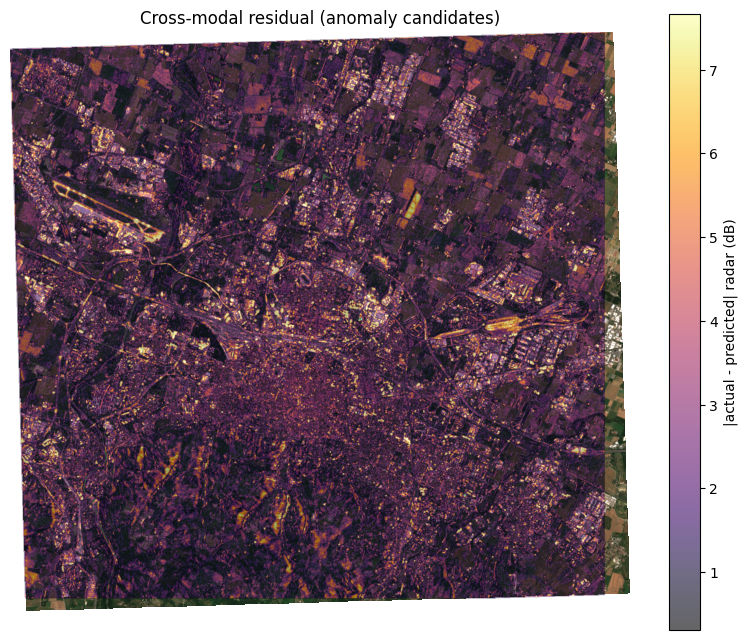

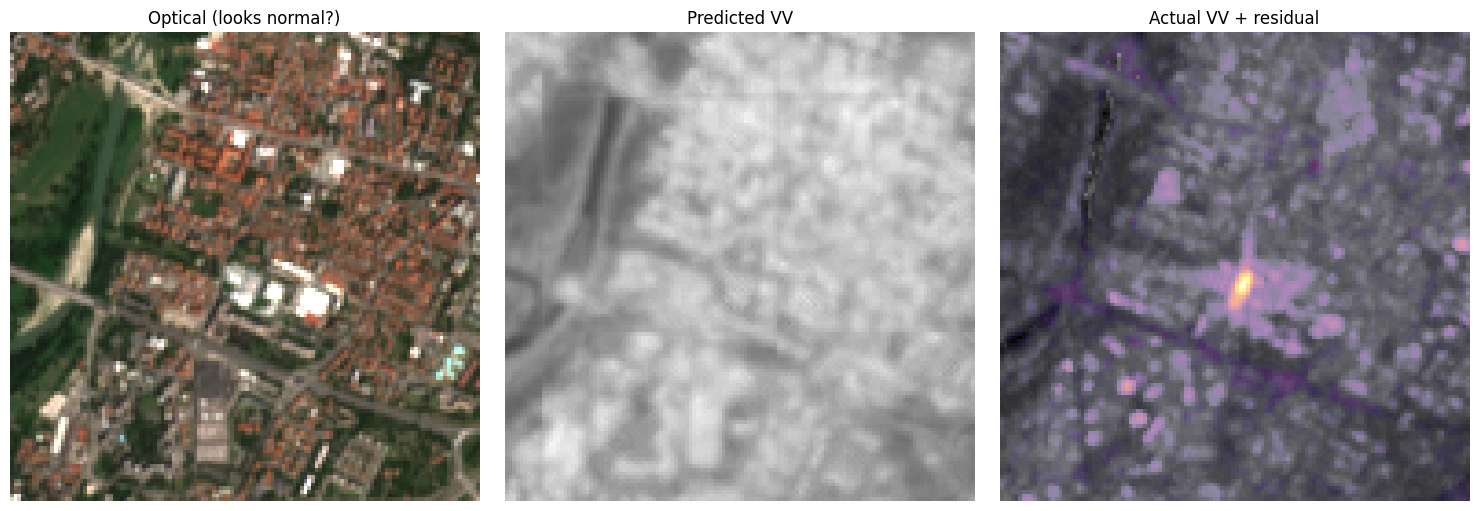

Hottest 100 m cell at grid (np.int64(75), np.int64(31)) - inspect the three-panel figure.


In [ ]:
OUT_DIR  = "/content/drive/MyDrive/q3_pipeline"
DRIVE_DIR = "/content/drive/MyDrive/GEE_exports"
SEASON_TIF = f"{DRIVE_DIR}/bologna_optical_sar_summer2023.tif"  # season to score
PATCH, STRIDE = 128, 64
CELL = 10                      # 10 px = 100 m aggregation cells
OPTICAL_IDX, RADAR_IDX = [0, 1, 2, 3], [4, 5]
NDWI_WATER_THRESHOLD = 0.2

import json, csv
import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt

exec(open(f"{OUT_DIR}/unet_def.py").read()) if False else None
# (U-Net class is redefined below to keep this file self-contained)

import torch.nn as nn
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
class UNet(nn.Module):
    def __init__(self, cin=4, cout=2, base=32):
        super().__init__()
        b = base
        self.e1 = conv_block(cin, b);      self.e2 = conv_block(b, 2*b)
        self.e3 = conv_block(2*b, 4*b);    self.e4 = conv_block(4*b, 8*b)
        self.pool = nn.MaxPool2d(2)
        self.u3 = nn.ConvTranspose2d(8*b, 4*b, 2, stride=2); self.d3 = conv_block(8*b, 4*b)
        self.u2 = nn.ConvTranspose2d(4*b, 2*b, 2, stride=2); self.d2 = conv_block(4*b, 2*b)
        self.u1 = nn.ConvTranspose2d(2*b, b,   2, stride=2); self.d1 = conv_block(2*b, b)
        self.head = nn.Conv2d(b, cout, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        d3 = self.d3(torch.cat([self.u3(e4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.head(d1)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = UNet().to(device)
model.load_state_dict(torch.load(f"{OUT_DIR}/best_model.pt", map_location=device))
model.eval()

with open(f"{OUT_DIR}/norm_stats.json") as fh:
    stats = json.load(fh)
MEAN = np.array(stats["mean"], dtype=np.float32)[:, None, None]
STD  = np.array(stats["std"],  dtype=np.float32)[:, None, None]

with rasterio.open(SEASON_TIF) as src:
    arr = src.read().astype(np.float32)          # (6, H, W)
    transform, crs = src.transform, src.crs
H, W = arr.shape[1:]

nodata = ~np.isfinite(arr).all(axis=0) | (arr[OPTICAL_IDX].sum(axis=0) == 0)
green, nir = arr[1], arr[3]
with np.errstate(divide="ignore", invalid="ignore"):
    ndwi = (green - nir) / (green + nir)
water = np.nan_to_num(ndwi, nan=0.0) > NDWI_WATER_THRESHOLD
invalid = nodata | water

arr_n = (np.nan_to_num(arr, nan=0.0) - MEAN) / STD
pred_sum = np.zeros((2, H, W), dtype=np.float32)
pred_cnt = np.zeros((H, W), dtype=np.float32)

with torch.no_grad():
    for r in range(0, H - PATCH + 1, STRIDE):
        for c in range(0, W - PATCH + 1, STRIDE):
            x = torch.from_numpy(arr_n[OPTICAL_IDX, r:r+PATCH, c:c+PATCH][None]).to(device)
            p = model(x)[0].cpu().numpy()
            pred_sum[:, r:r+PATCH, c:c+PATCH] += p
            pred_cnt[r:r+PATCH, c:c+PATCH]    += 1

valid_cnt = pred_cnt > 0
pred_norm = np.where(valid_cnt, pred_sum / np.maximum(pred_cnt, 1), np.nan)

pred_db   = pred_norm * STD[RADAR_IDX] + MEAN[RADAR_IDX]
actual_db = arr[RADAR_IDX]

residual = np.abs(actual_db - pred_db).mean(axis=0)        # (H, W), in dB
residual[invalid | ~valid_cnt] = np.nan
np.save(f"{OUT_DIR}/residual_map.npy", residual)
print(f"Residual map: median={np.nanmedian(residual):.2f} dB, "
      f"95th pct={np.nanpercentile(residual, 95):.2f} dB")

rows_c, cols_c = H // CELL, W // CELL
cells = np.full((rows_c, cols_c), np.nan, dtype=np.float32)
for i in range(rows_c):
    for j in range(cols_c):
        block = residual[i*CELL:(i+1)*CELL, j*CELL:(j+1)*CELL]
        if np.isfinite(block).mean() >= 0.5:       # cell must be mostly valid
            cells[i, j] = np.nanmean(block)

with open(f"{OUT_DIR}/anomaly_cells.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["cell_row", "cell_col", "easting", "northing", "residual_db"])
    for i in range(rows_c):
        for j in range(cols_c):
            if np.isfinite(cells[i, j]):
                px, py = j*CELL + CELL/2, i*CELL + CELL/2      # pixel center
                e, n = transform * (px, py)                    # to CRS coords
                w.writerow([i, j, f"{e:.1f}", f"{n:.1f}", f"{cells[i,j]:.3f}"])
np.save(f"{OUT_DIR}/anomaly_cells.npy", cells)
print(f"Aggregated to {np.isfinite(cells).sum()} valid 100 m cells "
      f"(CRS: {crs}).")

rgb = np.clip(np.stack([arr[2], arr[1], arr[0]], -1) / 0.3, 0, 1)

plt.figure(figsize=(10, 8))
plt.imshow(rgb)
im = plt.imshow(residual, cmap="inferno", alpha=0.6,
                vmin=np.nanpercentile(residual, 5),
                vmax=np.nanpercentile(residual, 99))
plt.colorbar(im, label="|actual - predicted| radar (dB)")
plt.title("Cross-modal residual (anomaly candidates)")
plt.axis("off")
plt.savefig(f"{OUT_DIR}/residual_heatmap.png", dpi=140); plt.show()

# three-panel over the hottest cell — your report figure
hot = np.unravel_index(np.nanargmax(cells), cells.shape)
r0, c0 = hot[0]*CELL - 64, hot[1]*CELL - 64
r0, c0 = max(0, min(r0, H-PATCH)), max(0, min(c0, W-PATCH))
sl = np.s_[r0:r0+PATCH, c0:c0+PATCH]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(rgb[sl]);                          ax[0].set_title("Optical (looks normal?)")
ax[1].imshow(pred_db[0][sl], cmap="gray", vmin=-20, vmax=0); ax[1].set_title("Predicted VV")
ax[2].imshow(actual_db[0][sl], cmap="gray", vmin=-20, vmax=0)
ax[2].imshow(residual[sl], cmap="inferno", alpha=0.5); ax[2].set_title("Actual VV + residual")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/three_panel.png", dpi=140); plt.show()
print("Hottest 100 m cell at grid", hot, "- inspect the three-panel figure.")

#Validate

114 test patches.
(A) BASELINE COMPARISON  (mean abs error in dB, lower=better)
    Model (optical -> radar):     1.652 dB
    Baseline (predict average):   3.252 dB
    Improvement:                  49.2%
    -> a clear improvement means the model learned real structure,
       not just the average radar value.
(B) SYNTHETIC ANOMALY DETECTION (AUC, 0.5=chance, 1.0=perfect)
    anomaly = +2 dB   ->   AUC = 0.666
    anomaly = +4 dB   ->   AUC = 0.874
    anomaly = +6 dB   ->   AUC = 0.965
    anomaly = +8 dB   ->   AUC = 0.990
    -> AUC rising toward 1.0 as anomaly strength grows means the
       residual reliably localises anomalies once they exceed the
       model's normal prediction noise.


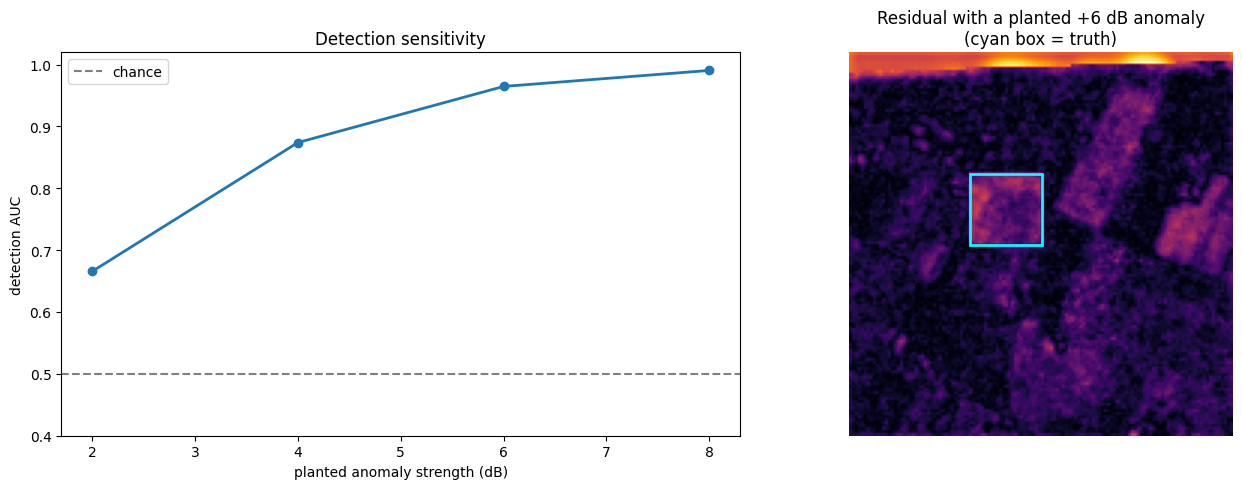

Saved validation_synthetic.png


In [ ]:
OUT_DIR = "/content/drive/MyDrive/q3_pipeline"
OPTICAL_IDX, RADAR_IDX = [0, 1, 2, 3], [4, 5]
INJECT_MAGNITUDES_DB = [2, 4, 6, 8]   # anomaly strengths to test
INJECT_SIZE = 24                       # side length (px) of each planted anomaly
N_INJECT_PER_TILE = 1
SEED = 0

import json, csv, random
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
class UNet(nn.Module):
    def __init__(self, cin=4, cout=2, base=32):
        super().__init__(); b = base
        self.e1 = conv_block(cin, b);   self.e2 = conv_block(b, 2*b)
        self.e3 = conv_block(2*b, 4*b); self.e4 = conv_block(4*b, 8*b)
        self.pool = nn.MaxPool2d(2)
        self.u3 = nn.ConvTranspose2d(8*b, 4*b, 2, stride=2); self.d3 = conv_block(8*b, 4*b)
        self.u2 = nn.ConvTranspose2d(4*b, 2*b, 2, stride=2); self.d2 = conv_block(4*b, 2*b)
        self.u1 = nn.ConvTranspose2d(2*b, b,   2, stride=2); self.d1 = conv_block(2*b, b)
        self.head = nn.Conv2d(b, cout, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        d3 = self.d3(torch.cat([self.u3(e4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.head(d1)

model = UNet().to(device)
model.load_state_dict(torch.load(f"{OUT_DIR}/best_model.pt", map_location=device))
model.eval()

with open(f"{OUT_DIR}/norm_stats.json") as fh:
    stats = json.load(fh)
MEAN = np.array(stats["mean"], dtype=np.float32)[:, None, None]
STD  = np.array(stats["std"],  dtype=np.float32)[:, None, None]
MEAN_R = MEAN[RADAR_IDX]; STD_R = STD[RADAR_IDX]

with open(f"{OUT_DIR}/manifest.csv") as fh:
    test_recs = [r for r in csv.DictReader(fh) if r["split"] == "test"]
print(f"{len(test_recs)} test patches.")

def predict_radar_db(optical_norm):
    """optical_norm: (4,H,W) normalized -> predicted radar in dB (2,H,W)."""
    with torch.no_grad():
        x = torch.from_numpy(optical_norm[None]).to(device)
        p = model(x)[0].cpu().numpy()
    return p * STD_R + MEAN_R

model_err, mean_err = [], []
mean_radar_db = MEAN_R[:, 0, 0]        # the trivial "predict the average" guess
for r in test_recs:
    p = np.nan_to_num(np.load(f"{OUT_DIR}/{r['file']}"), nan=0.0)
    optical_norm = ((p - MEAN) / STD)[OPTICAL_IDX]
    actual_db = p[RADAR_IDX]
    pred_db = predict_radar_db(optical_norm)
    model_err.append(np.abs(actual_db - pred_db).mean())
    mean_err.append(np.abs(actual_db - mean_radar_db[:, None, None]).mean())
model_err, mean_err = np.mean(model_err), np.mean(mean_err)
print("=" * 55)
print("(A) BASELINE COMPARISON  (mean abs error in dB, lower=better)")
print(f"    Model (optical -> radar):     {model_err:.3f} dB")
print(f"    Baseline (predict average):   {mean_err:.3f} dB")
print(f"    Improvement:                  {100*(1-model_err/mean_err):.1f}%")
print("    -> a clear improvement means the model learned real structure,")
print("       not just the average radar value.")

def roc_auc(scores, labels):
    order = np.argsort(scores); ranks = np.empty(len(scores))
    ranks[order] = np.arange(1, len(scores) + 1)
    p, n = labels.sum(), (1 - labels).sum()
    if p == 0 or n == 0: return float("nan")
    return (ranks[labels == 1].sum() - p * (p + 1) / 2) / (p * n)

print("=" * 55)
print("(B) SYNTHETIC ANOMALY DETECTION (AUC, 0.5=chance, 1.0=perfect)")
results = {}
for mag in INJECT_MAGNITUDES_DB:
    all_scores, all_labels = [], []
    for r in test_recs:
        p = np.nan_to_num(np.load(f"{OUT_DIR}/{r['file']}"), nan=0.0)
        optical_norm = ((p - MEAN) / STD)[OPTICAL_IDX]
        actual_db = p[RADAR_IDX].copy()
        _, Hh, Ww = actual_db.shape
        # plant anomaly: raise radar backscatter by `mag` dB in a random box
        label = np.zeros((Hh, Ww), dtype=np.uint8)
        for _ in range(N_INJECT_PER_TILE):
            i = random.randint(0, Hh - INJECT_SIZE)
            j = random.randint(0, Ww - INJECT_SIZE)
            actual_db[:, i:i+INJECT_SIZE, j:j+INJECT_SIZE] += mag
            label[i:i+INJECT_SIZE, j:j+INJECT_SIZE] = 1
        pred_db = predict_radar_db(optical_norm)          # prediction unaffected
        residual = np.abs(actual_db - pred_db).mean(axis=0)   # (H,W)
        all_scores.append(residual.ravel())
        all_labels.append(label.ravel())
    scores = np.concatenate(all_scores); labels = np.concatenate(all_labels)
    auc = roc_auc(scores, labels)
    results[mag] = auc
    print(f"    anomaly = +{mag} dB   ->   AUC = {auc:.3f}")
print("    -> AUC rising toward 1.0 as anomaly strength grows means the")
print("       residual reliably localises anomalies once they exceed the")
print("       model's normal prediction noise.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

mags = list(results.keys()); aucs = [results[m] for m in mags]
ax[0].plot(mags, aucs, "o-", lw=2)
ax[0].axhline(0.5, ls="--", c="gray", label="chance")
ax[0].set_xlabel("planted anomaly strength (dB)")
ax[0].set_ylabel("detection AUC")
ax[0].set_ylim(0.4, 1.02); ax[0].legend()
ax[0].set_title("Detection sensitivity")

r = test_recs[len(test_recs)//2]
p = np.nan_to_num(np.load(f"{OUT_DIR}/{r['file']}"), nan=0.0)
optical_norm = ((p - MEAN) / STD)[OPTICAL_IDX]
actual_db = p[RADAR_IDX].copy()
i, j, m = 40, 40, INJECT_SIZE
actual_db[:, i:i+m, j:j+m] += 6
pred_db = predict_radar_db(optical_norm)
residual = np.abs(actual_db - pred_db).mean(axis=0)
ax[1].imshow(residual, cmap="inferno")
ax[1].add_patch(plt.Rectangle((j, i), m, m, fill=False, ec="cyan", lw=2))
ax[1].set_title("Residual with a planted +6 dB anomaly\n(cyan box = truth)")
ax[1].axis("off")

plt.tight_layout(); plt.savefig(f"{OUT_DIR}/validation_synthetic.png", dpi=140)
plt.show()
print("Saved validation_synthetic.png")